In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashishjangra27/face-mask-12k-images-dataset")

print("Path to dataset files:", path)

100%|██████████| 330M/330M [00:02<00:00, 160MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ashishjangra27/face-mask-12k-images-dataset/versions/1


In [4]:
import os
print(os.listdir(path))

['Face Mask Dataset']


In [5]:
import os

dataset_root = os.path.join(path, "Face Mask Dataset")

print(os.listdir(dataset_root))

['Train', 'Validation', 'Test']


In [6]:
for root, dirs, files in os.walk(dataset_root):
    level = root.replace(dataset_root, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            dirs[:] = []

Face Mask Dataset/
  Train/
    WithoutMask/
    WithMask/
  Validation/
    WithoutMask/
    WithMask/
  Test/
    WithoutMask/
    WithMask/


In [8]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader,TensorDataset
import torchvision.transforms as transforms

In [28]:
torch.manual_seed(42)

In [29]:
train_tranform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [21]:
evel_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [22]:
train_dir = os.path.join(dataset_root,"Train")
test_dir = os.path.join(dataset_root,"Test")
val_dir = os.path.join(dataset_root,"Validation")
print("Training :",os.listdir(train_dir))
print("Testing :",os.listdir(test_dir))
print("Validation :",os.listdir(val_dir))

Training : ['WithoutMask', 'WithMask']
Testing : ['WithoutMask', 'WithMask']
Validation : ['WithoutMask', 'WithMask']


In [23]:
from torchvision import datasets

In [24]:
train_dataset = datasets.ImageFolder(train_dir,transform=train_tranform)
test_dataset = datasets.ImageFolder(test_dir,transform=evel_transform)
val_dataset = datasets.ImageFolder(val_dir,transform=evel_transform)

In [25]:
print("Classes :",train_dataset.classes)
print("Class mapping :",train_dataset.class_to_idx)
print("Training images :",len(train_dataset))
print("Testing images :",len(test_dataset))
print("Validation images :",len(val_dataset))

Classes : ['WithMask', 'WithoutMask']
Class mapping : {'WithMask': 0, 'WithoutMask': 1}
Training images : 10000
Testing images : 992
Validation images : 800


In [26]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)

In [40]:
class CNN(nn.Module):
  def __init__(self):
      super(CNN,self).__init__()

      self.conv_layers = nn.Sequential(
          nn.Conv2d(3,16,kernel_size=3,padding=1),
          nn.BatchNorm2d(16),
          nn.ReLU(),
          nn.MaxPool2d(2,2),

          nn.Conv2d(16,32,kernel_size=3,padding=1),
          nn.BatchNorm2d(32),
          nn.ReLU(),
          nn.MaxPool2d(2,2),

          nn.Conv2d(32,64,kernel_size=3,padding=1),
          nn.BatchNorm2d(64),
          nn.ReLU(),
          nn.MaxPool2d(2,2),

          nn.Conv2d(64,128,kernel_size=3,padding=1),
          nn.BatchNorm2d(128),
          nn.ReLU(),
          nn.MaxPool2d(2,2),

          nn.Conv2d(128,256,kernel_size=3,padding=1),
          nn.BatchNorm2d(256),
          nn.ReLU(),
          nn.MaxPool2d(2,2),

        )

      self.fully_connected_layer = nn.Sequential(
          nn.Linear(256*7*7,1024),
          nn.ReLU(),
          nn.Dropout(0.5),

          nn.Linear(1024,512),
          nn.ReLU(),
          nn.Dropout(0.5),
          nn.Linear(512,2),
      )

  def forward(self, x):
    out = self.conv_layers(x)
    out = torch.flatten(out,start_dim=1)
    out = self.fully_connected_layer(out)
    return out

In [41]:
model = CNN()
criterian = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.001)

In [42]:
# Check and select GPU (T4) if available, otherwise fallback to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move your model to the GPU
model = model.to(device)

Using device: cuda


In [43]:
epochs = 10
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
  model.train()
  running_train_loss = 0.0
  correct_train = 0
  total_train = 0
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterian(outputs,labels)
    loss.backward()
    optimizer.step()

    running_train_loss += loss.item() * images.size(0)
    _, predicted = torch.max(outputs.data, 1)
    total_train += labels.size(0)
    correct_train += (predicted == labels).sum().item()

  epoch_train_loss = running_train_loss / len(train_loader)
  epoch_train_accuracy = 100 * correct_train / total_train
  train_losses.append(epoch_train_loss)
  train_accuracies.append(epoch_train_accuracy)

  # evaluation
  model.eval()
  running_val_loss = 0.0
  correct_val = 0
  total_val = 0

  with torch.no_grad():
    for images,labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterian(outputs,labels)
      running_val_loss += loss.item() * images.size(0)
      _, predicted = torch.max(outputs.data, 1)
      total_val += labels.size(0)
      correct_val += (predicted == labels).sum().item()
  epoch_val_loss = running_val_loss / len(val_loader)
  epoch_val_accuracy = 100 * correct_val / total_val
  val_losses.append(epoch_val_loss)
  val_accuracies.append(epoch_val_accuracy)

  print(
      f"Epoch [{epoch+1}/{epochs}] | "
      f"Train Loss: {epoch_train_loss:.4f}, Acc: {epoch_train_accuracy:.2f}% | "
      f"Val Loss: {epoch_val_loss:.4f}, Acc: {epoch_val_accuracy:.2f}%")

Epoch [1/10] | Train Loss: 7.5660, Acc: 94.22% | Val Loss: 3.0762, Acc: 97.12%
Epoch [2/10] | Train Loss: 2.7566, Acc: 97.45% | Val Loss: 2.3265, Acc: 97.38%
Epoch [3/10] | Train Loss: 2.0005, Acc: 98.11% | Val Loss: 0.9624, Acc: 99.12%
Epoch [4/10] | Train Loss: 1.4115, Acc: 98.63% | Val Loss: 0.7850, Acc: 98.88%
Epoch [5/10] | Train Loss: 1.2478, Acc: 98.85% | Val Loss: 0.5915, Acc: 99.38%
Epoch [6/10] | Train Loss: 1.3894, Acc: 98.57% | Val Loss: 3.4267, Acc: 98.50%
Epoch [7/10] | Train Loss: 1.3384, Acc: 98.82% | Val Loss: 0.4041, Acc: 99.75%
Epoch [8/10] | Train Loss: 1.0671, Acc: 99.10% | Val Loss: 0.4300, Acc: 99.50%
Epoch [9/10] | Train Loss: 0.6583, Acc: 99.43% | Val Loss: 0.4731, Acc: 99.62%
Epoch [10/10] | Train Loss: 1.4202, Acc: 98.96% | Val Loss: 1.0571, Acc: 99.00%


In [45]:
model.eval()
test_loss = 0.0
correct_test = 0
total_test = 0

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    outputs = model(images)
    loss = criterian(outputs, labels)

    test_loss += loss.item() * images.size(0)
    _, predicted = torch.max(outputs, 1)
    correct_test += (predicted == labels).sum().item()
    total_test += labels.size(0)

print(f"Test Loss: {test_loss / total_test:.4f}")
print(f"Test Accuracy: {(correct_test / total_test) * 100:.2f}%")

Test Loss: 0.0793
Test Accuracy: 98.79%


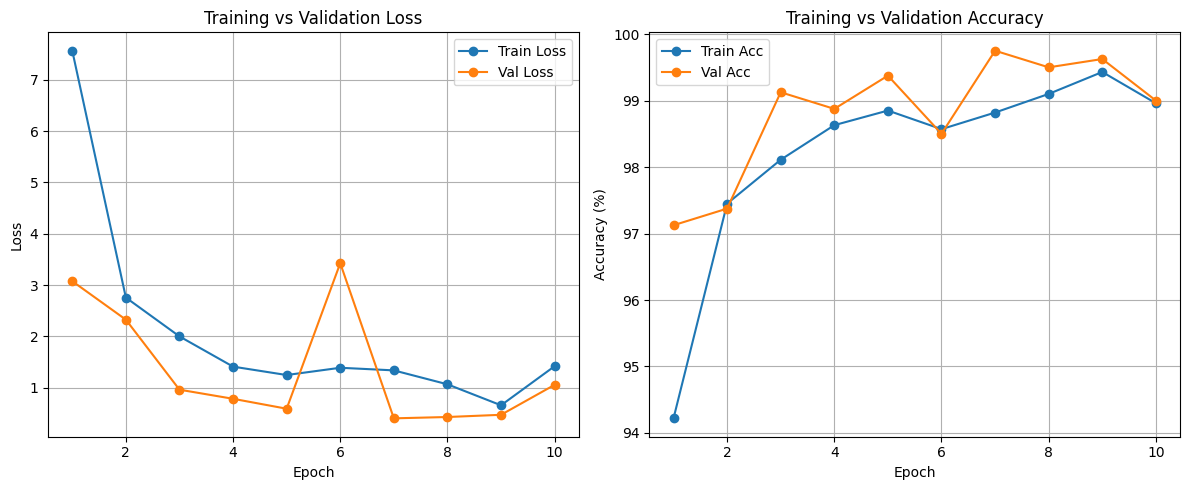

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, label="Train Loss", marker="o")
plt.plot(range(1, epochs + 1), val_losses, label="Val Loss", marker="o")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_accuracies, label="Train Acc", marker="o")
plt.plot(range(1, epochs + 1), val_accuracies, label="Val Acc", marker="o")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [48]:
# Save weights
torch.save(model.state_dict(), "face_mask_cnn.pth")
print("Model saved successfully as face_mask_cnn.pth")

Model saved successfully as face_mask_cnn.pth


In [49]:
from PIL import Image

# Class names matching dataset index: 0 -> WithMask, 1 -> WithoutMask
classes = ["WithMask", "WithoutMask"]


def predict_image(image_path, model):
  image = Image.open(image_path).convert("RGB")
  input_tensor = evel_transform(image).unsqueeze(0).to(device)

  model.eval()
  with torch.no_grad():
    output = model(input_tensor)
    prob = torch.softmax(output, dim=1)
    confidence, predicted_idx = torch.max(prob, 1)

  label = classes[predicted_idx.item()]
  conf_score = confidence.item() * 100
  print(f"Prediction: {label} ({conf_score:.2f}% confidence)")
  return label, conf_score


# Example test using an image from the test set:
sample_img = os.path.join(test_dir, "WithMask", os.listdir(os.path.join(test_dir, "WithMask"))[0])
predict_image(sample_img, model)

Prediction: WithMask (100.00% confidence)


('WithMask', 100.0)

In [50]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

all_preds = []
all_targets = []

model.eval()
with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    outputs = model(images)
    _, preds = torch.max(outputs, 1)
    all_preds.extend(preds.cpu().numpy())
    all_targets.extend(labels.numpy())

print("Confusion Matrix:")
print(confusion_matrix(all_targets, all_preds))
print("\nClassification Report:")
print(classification_report(all_targets, all_preds, target_names=["WithMask", "WithoutMask"]))

Confusion Matrix:
[[475   8]
 [  4 505]]

Classification Report:
              precision    recall  f1-score   support

    WithMask       0.99      0.98      0.99       483
 WithoutMask       0.98      0.99      0.99       509

    accuracy                           0.99       992
   macro avg       0.99      0.99      0.99       992
weighted avg       0.99      0.99      0.99       992



In [60]:
print(model)

print("\n" + "=" * 60)
print(f"{'Layer / Parameter Name':<40} {'Shape':<15} {'Count'}")
print("=" * 60)

total_params = 0
for name, param in model.named_parameters():
  num_params = param.numel()
  total_params += num_params
  print(f"{name:<40} {str(list(param.shape)):<15} {num_params:,}")

print("=" * 60)
print(f"Total Parameters: {total_params:,}")

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (